In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from apyori import apriori

In [3]:
df=pd.read_csv("Market_Basket_Optimisation.csv")
transactions=[[str(x) for x in row if str(x)!='nan']for row in df.values]

In [4]:
rules=list(apriori(transactions,min_support=0.003,min_confidence=0.2,min_lift=3,min_length=2))
print("no of rules: ",len(rules))

no of rules:  80


In [8]:
rows = []
for r in rules:
    for s in r.ordered_statistics:
        rows.append([", ".join(s.items_base), ", ".join(s.items_add),
                     r.support, s.confidence, s.lift])
rules_df = pd.DataFrame(rows, columns=["If bought", "Then buys", "Support", "Confidence", "Lift"])
rules_df = rules_df.sort_values("Confidence", ascending=False).reset_index(drop=True)
print(rules_df.head(10))

                                   If bought      Then buys   Support  \
0              soup, frozen vegetables, milk  mineral water  0.003067   
1                       cereals, ground beef      spaghetti  0.003067   
2                        olive oil, tomatoes      spaghetti  0.004400   
3     mineral water, soup, frozen vegetables           milk  0.003067   
4                  tomato sauce, ground beef      spaghetti  0.003067   
5                   ground beef, cooking oil      spaghetti  0.004800   
6       mineral water, tomatoes, ground beef      spaghetti  0.003067   
7       milk, frozen vegetables, ground beef      spaghetti  0.003067   
8  chocolate, frozen vegetables, ground beef      spaghetti  0.003067   
9                             red wine, eggs      spaghetti  0.003733   

   Confidence      Lift  
0    0.766667  3.217683  
1    0.676471  3.884785  
2    0.611111  3.509444  
3    0.605263  4.670240  
4    0.575000  3.302067  
5    0.571429  3.281558  
6    0.560976 

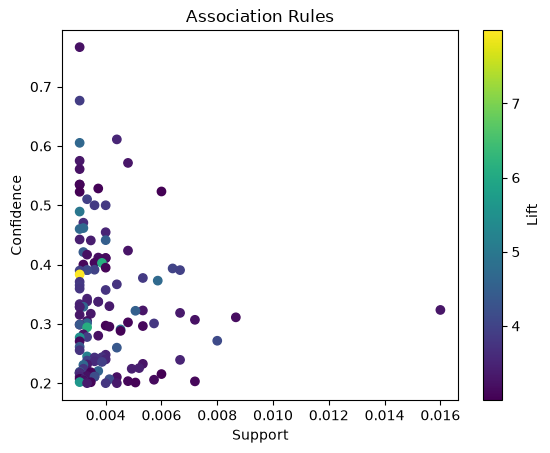

In [12]:
plt.scatter(rules_df["Support"], rules_df["Confidence"], c=rules_df["Lift"], cmap="viridis")
plt.colorbar(label="Lift")
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.title("Association Rules")
plt.show()